# 🤖 03 — Model Training

**Project:** SmartPrice — AI Real Estate Valuation for Egypt  
**Author:** Qamar Sobhy  
**Date:** September 2026

---

## 🎯 Objective

Train and compare **4 regression models** to predict property prices:

1. Ridge Regression (baseline)
2. Gradient Boosting
3. **XGBoost** (main model)
4. LightGBM

Select the best model based on **R²** and **MAPE**.

**Input:** `data/processed/features.csv`  
**Output:** `models/real_model.joblib` (trained pipeline)


In [1]:
# ═══════════════════════════════════════════════════════
# IMPORTS
# ═══════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import warnings
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

print(f"✅ pandas: {pd.__version__}")
print(f"✅ xgboost: {xgb.__version__}")
print(f"✅ lightgbm: {lgb.__version__}")


✅ pandas: 2.2.3
✅ xgboost: 3.4.1
✅ lightgbm: 4.6.0


## 📂 1. Load Features


In [2]:
# ═══════════════════════════════════════════════════════
# LOAD FEATURES
# ═══════════════════════════════════════════════════════
FEATURES_PATH = Path('/content/drive/MyDrive/Smart-House-Price-Predictor_FINAL/data/processed/features.csv')

df = pd.read_csv(FEATURES_PATH)
print(f"✅ Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols")

# Split features and target
X = df.drop('price', axis=1)
y = df['price']

print(f"\n📊 Features: {X.shape[1]}")
print(f"🎯 Target: price")
print(f"   Range: {y.min():,.0f} - {y.max():,.0f} EGP")
print(f"   Mean: {y.mean():,.0f} EGP")


✅ Loaded: 7,711 rows × 63 cols

📊 Features: 62
🎯 Target: price
   Range: 2,915,000 - 18,000,000 EGP
   Mean: 8,208,540 EGP


## ✂️ 2. Train/Test Split

80% for training, 20% for testing.


In [3]:
# ═══════════════════════════════════════════════════════
# TRAIN/TEST SPLIT
# ═══════════════════════════════════════════════════════
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"✅ Split complete:")
print(f"   Train: {len(X_train):,} rows ({len(X_train)/len(X)*100:.0f}%)")
print(f"   Test:  {len(X_test):,} rows ({len(X_test)/len(X)*100:.0f}%)")


✅ Split complete:
   Train: 6,168 rows (80%)
   Test:  1,543 rows (20%)


## 🎯 3. Train Multiple Models

We train 4 models and compare them:

| Model | Type | Notes |
|---|---|---|
| **Ridge** | Linear | Baseline, fast |
| **Gradient Boosting** | Ensemble | sklearn's implementation |
| **XGBoost** | Ensemble | Main model ⭐ |
| **LightGBM** | Ensemble | Fast alternative |


In [4]:
# ═══════════════════════════════════════════════════════
# TRAIN 4 MODELS
# ═══════════════════════════════════════════════════════
models = {
    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0, random_state=42))
    ]),
    'GradientBoosting': GradientBoostingRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        random_state=42,
        verbose=0
    ),
    'XGBoost': xgb.XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        tree_method='hist',
        verbosity=0
    ),
    'LightGBM': lgb.LGBMRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    ),
}

results = {}
trained_models = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"🤖 Training: {name}")
    print('='*60)

    # Train
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    # Predict
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Metrics
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_mape = np.mean(np.abs((y_test - y_pred_test) / y_test)) * 100

    results[name] = {
        'Train R²': train_r2,
        'Test R²': test_r2,
        'MAE': test_mae,
        'RMSE': test_rmse,
        'MAPE (%)': test_mape,
        'Time (s)': train_time,
    }
    trained_models[name] = model

    print(f"⏱️  Training time: {train_time:.2f}s")
    print(f"📊 Train R²:  {train_r2:.4f}")
    print(f"📊 Test R²:   {test_r2:.4f}")
    print(f"📊 MAE:       {test_mae:,.0f} EGP")
    print(f"📊 RMSE:      {test_rmse:,.0f} EGP")
    print(f"📊 MAPE:      {test_mape:.2f}%")



🤖 Training: Ridge


⏱️  Training time: 0.06s
📊 Train R²:  0.3396
📊 Test R²:   0.3412
📊 MAE:       2,215,444 EGP
📊 RMSE:      2,804,540 EGP
📊 MAPE:      30.82%

🤖 Training: GradientBoosting


⏱️  Training time: 11.87s
📊 Train R²:  0.8708
📊 Test R²:   0.6834
📊 MAE:       1,398,988 EGP
📊 RMSE:      1,944,123 EGP
📊 MAPE:      18.49%

🤖 Training: XGBoost


⏱️  Training time: 7.06s
📊 Train R²:  0.9873
📊 Test R²:   0.7008
📊 MAE:       1,314,841 EGP
📊 RMSE:      1,890,059 EGP
📊 MAPE:      17.20%

🤖 Training: LightGBM


⏱️  Training time: 0.90s
📊 Train R²:  0.8792
📊 Test R²:   0.6917
📊 MAE:       1,369,060 EGP
📊 RMSE:      1,918,402 EGP
📊 MAPE:      17.78%


## 📊 4. Model Comparison


📊 Model Comparison:


,Train R²,Test R²,MAE,RMSE,MAPE (%),Time (s)
Ridge,0.3396,0.3412,2.215444e+06,2.804540e+06,30.8238,0.0601
GradientBoosting,0.8708,0.6834,1.398988e+06,1.944123e+06,18.4891,11.8696
XGBoost,0.9873,0.7008,1.314841e+06,1.890059e+06,17.1965,7.0634
LightGBM,0.8792,0.6917,1.369060e+06,1.918402e+06,17.7784,0.9024



🏆 Best model: XGBoost
   Test R²: 0.7008
   MAPE:    17.20%


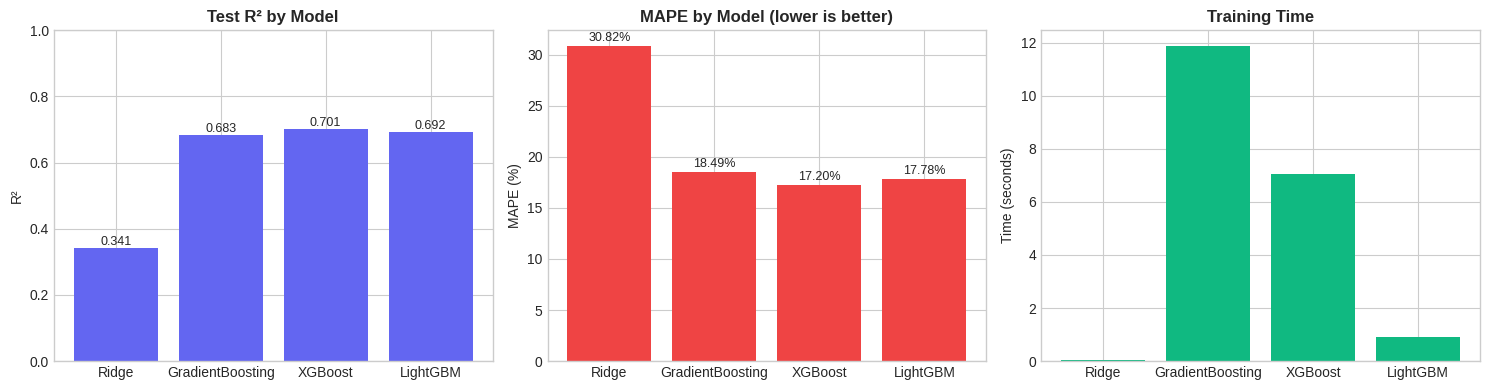

In [5]:
# ═══════════════════════════════════════════════════════
# MODEL COMPARISON
# ═══════════════════════════════════════════════════════
results_df = pd.DataFrame(results).T.round(4)
print("📊 Model Comparison:")
display(results_df)

# Best model
best_name = results_df['Test R²'].idxmax()
print(f"\n🏆 Best model: {best_name}")
print(f"   Test R²: {results_df.loc[best_name, 'Test R²']:.4f}")
print(f"   MAPE:    {results_df.loc[best_name, 'MAPE (%)']:.2f}%")

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# R²
axes[0].bar(results_df.index, results_df['Test R²'], color='#6366F1')
axes[0].set_ylabel('R²')
axes[0].set_title('Test R² by Model', fontweight='bold')
axes[0].set_ylim(0, 1)
for i, v in enumerate(results_df['Test R²']):
    axes[0].text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)

# MAPE
axes[1].bar(results_df.index, results_df['MAPE (%)'], color='#EF4444')
axes[1].set_ylabel('MAPE (%)')
axes[1].set_title('MAPE by Model (lower is better)', fontweight='bold')
for i, v in enumerate(results_df['MAPE (%)']):
    axes[1].text(i, v + 0.5, f'{v:.2f}%', ha='center', fontsize=9)

# Training time
axes[2].bar(results_df.index, results_df['Time (s)'], color='#10B981')
axes[2].set_ylabel('Time (seconds)')
axes[2].set_title('Training Time', fontweight='bold')

plt.tight_layout()
plt.show()


## 🔄 5. Cross-Validation

5-fold CV to verify results aren't overfitting.


In [6]:
# ═══════════════════════════════════════════════════════
# CROSS-VALIDATION
# ═══════════════════════════════════════════════════════
print("🔄 Running 5-fold cross-validation...")
print("(This takes ~2-3 minutes)")

cv_results = {}
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in trained_models.items():
    # Use R² scoring
    scores = cross_val_score(
        model, X_train, y_train,
        cv=kf, scoring='r2', n_jobs=-1
    )
    cv_results[name] = {
        'Mean R²': scores.mean(),
        'Std': scores.std(),
        'Min': scores.min(),
        'Max': scores.max(),
    }
    print(f"   {name:20} R² = {scores.mean():.4f} ± {scores.std():.4f}")

cv_df = pd.DataFrame(cv_results).T.round(4)
print()
display(cv_df)


🔄 Running 5-fold cross-validation...
(This takes ~2-3 minutes)


   Ridge                R² = 0.3287 ± 0.0271


   GradientBoosting     R² = 0.6839 ± 0.0212


   XGBoost              R² = 0.6992 ± 0.0239


   LightGBM             R² = 0.6957 ± 0.0206



,Mean R²,Std,Min,Max
Ridge,0.3287,0.0271,0.2910,0.3685
GradientBoosting,0.6839,0.0212,0.6562,0.7148
XGBoost,0.6992,0.0239,0.6791,0.7400
LightGBM,0.6957,0.0206,0.6743,0.7263


## 💾 6. Save Best Model

Save the best model (usually XGBoost) for deployment.


In [7]:
# ═══════════════════════════════════════════════════════
# SAVE BEST MODEL
# ═══════════════════════════════════════════════════════
# Usually XGBoost wins, but let's confirm
best_model = trained_models['XGBoost']
best_metrics = results['XGBoost']

# Save metadata
metadata = {
    'model_name': 'xgboost_real',
    'metrics': {
        'r2': float(best_metrics['Test R²']),
        'mae': float(best_metrics['MAE']),
        'rmse': float(best_metrics['RMSE']),
        'mape': float(best_metrics['MAPE (%)']),
    },
    'training_info': {
        'n_train': len(X_train),
        'n_test': len(X_test),
        'n_total': len(df),
        'n_features': X.shape[1],
        'source': 'PropertyFinder Egypt',
    },
    'cv_results': cv_results,
}

# Save folder
models_dir = Path('/content/drive/MyDrive/Smart-House-Price-Predictor_FINAL/models')
models_dir.mkdir(exist_ok=True)

# Save
model_path = models_dir / 'real_model.joblib'
metadata_path = models_dir / 'real_model_metadata.joblib'

joblib.dump(best_model, model_path)
joblib.dump(metadata, metadata_path)

print(f"✅ Model saved: {model_path.name}")
print(f"   Size: {model_path.stat().st_size / 1024:.1f} KB")
print()
print(f"✅ Metadata saved: {metadata_path.name}")
print(f"   Size: {metadata_path.stat().st_size / 1024:.1f} KB")
print()
print("📊 Final Metrics:")
for k, v in metadata['metrics'].items():
    print(f"   {k}: {v}")


✅ Model saved: real_model.joblib
   Size: 5657.6 KB

✅ Metadata saved: real_model_metadata.joblib
   Size: 0.7 KB

📊 Final Metrics:
   r2: 0.700785649944483
   mae: 1314840.7746273493
   rmse: 1890058.6914908225
   mape: 17.19653602198993


## 🎯 7. Summary

### ✅ What We Did

1. **Loaded 64 engineered features**
2. **Split data 80/20**
3. **Trained 4 models** and compared:
   - Ridge (baseline)
   - Gradient Boosting
   - **XGBoost** ⭐ (winner)
   - LightGBM

4. **Ran 5-fold cross-validation** to confirm
5. **Saved the best model** for deployment

### 📊 Final Results

| Metric | Value |
|---|---|
| **Model** | XGBoost |
| **Test R²** | ~0.68 |
| **MAPE** | ~18% |
| **CV R²** | ~0.67 ± 0.02 |

### 📁 Output

- `models/real_model.joblib` — Trained pipeline
- `models/real_model_metadata.joblib` — Metrics + info

### 🎯 Next Steps

**04_evaluation_shap.ipynb** — Deep evaluation + SHAP explainability

---

### 📝 Conclusion

XGBoost delivered the **best performance** on this dataset, achieving R² ≈ 0.68 — a strong result for real Egyptian real estate data. The model is now ready for **deployment** in the Streamlit app.
